# 較正データのバックプロジェクション

較正線源の測定データから、ETCC の特徴である**イベントごとの到来方向**を線源の平面に投影(バックプロジェクション)して、
線源の像を作ります。

- 再構成ツリーの作り方: `../DataIO/`
- イベント選択の中身: `../EventSelection/`

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください
  (Jupyter を起動する前に `export SMILE2P_DATA=/path/to/data`)。
- 上の形(`<置き場>/Per02_ETCC`、`<置き場>/param/20190528`)で置けば設定ファイルは書き換え不要です。
  置き方が違う場合は、設定ファイル `config/smile2p_20190701_Per02.json` の
  `ReadData.data_dir`、`TPC_Calibration.ParameterFile`、`HA_Calc.parameter_dir`、
  `HA_Calc.Modified_Parameter_Data_Dir`、`TOT_Skewness.drift_velocity_file` を自分のパスに書き換えます
  (詳しくはリポジトリ直下の README の「自分の環境に合わせて変える場所」)。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

設定ファイル `config/smile2p_20190701_Per02.json` に、データの場所(`{data_top}` はデータの置き場に置き換わる)と
各モジュールのパラメータが書かれています。データが見つかるか確認します(`MISSING` なら上のコマンドでコピー)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. 再構成データとイベント選択

DataIO と同じチェーンの出力(先頭 50000 イベント、`tutorials/cache/` で共有)を読み、
本番解析と同じイベント選択(`SetCrit`。各カットの意味と分布は `../EventSelection/`)をすべて掛けます。

In [3]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_50000.root -n 50000


In [4]:
d = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).Filter("err_flag == 0").AsNumpy(
    ["Eg", "Ke", "Len_TRA", "alpha_kin", "Pg", "Pe_TRA", "Ve_TRA", "Track_Min", "Track_Max"])
Eg, Ke, Len, alpha_kin = d["Eg"], d["Ke"], d["Len_TRA"], d["alpha_kin"]
Pg = vec(d["Pg"])
Pe, Ve = vec(d["Pe_TRA"])[:, :3], vec(d["Ve_TRA"])[:, :3]   # 6 要素のうち使うのは先頭 3 つ
TrkMin, TrkMax = vec(d["Track_Min"]), vec(d["Track_Max"])
print("err_flag == 0:", len(Eg))

MC2 = 510.9989461   # keV(SMLib Compton_common::mass_e)

# cos α_geo: 散乱ガンマ線の向き ĝ = (Pg - Pe)/|Pg - Pe| と電子の向き ê = Ve/|Ve| の内積
g_unit = (Pg - Pe) / np.linalg.norm(Pg - Pe, axis=1, keepdims=True)
e_unit = Ve / np.linalg.norm(Ve, axis=1, keepdims=True)
dcos = np.sum(g_unit * e_unit, axis=1) - np.cos(np.radians(alpha_kin))   # cos α_geo - cos α_kin
ke, eg = Ke / 1000., Eg / 1000.   # MeV

with np.errstate(invalid="ignore"):
    cuts = {
        "Eg": (eg >= 0.15) & (eg <= 2.1),
        "fiducial": ((-153.6 + 5. < TrkMin[:, 0]) & (TrkMax[:, 0] < -5. + 153.6)
                     & (-153.6 + 5. < TrkMin[:, 1]) & (TrkMax[:, 1] < -5. + 153.6)
                     & (27.0 + 5. < TrkMin[:, 2]) & (TrkMax[:, 2] < -5. + 332.0)),
        "dEdx": ((Len < 1975.9 * np.power(ke, 1.4) + 7.)
                 & (Len > 913.9 * np.power(ke, 2.0) + 2.2)
                 & (Len < 270.)),
        "dcos_alpha": (-0.5 <= dcos) & (dcos <= 0.5),
    }
sel = cuts["Eg"] & cuts["fiducial"] & cuts["dEdx"] & cuts["dcos_alpha"]
print("selected:", sel.sum())

err_flag == 0: 26697
selected: 4887


## 3. バックプロジェクション像

ETCC は散乱ガンマ線の向きだけでなく反跳電子の向きも測るので、運動量保存から
入射ガンマ線の方向をイベントごとに 1 本の直線として決められます
(参照 `Compton_common::recon_vector` と同じ式):

$$\hat r = \frac{E_g\,\hat g + K_e\sqrt{1 + 2m_ec^2/K_e}\;\hat e}{\left|\,\cdots\right|}$$

$\hat r$ は**線源から検出器へ向かう**向きなので、散乱点 `Pe` から線源の平面
(`z = -1626 mm`, 参照の `Source_Position_Z`)まで戻る距離は
`d = -(Pe_z - z_src) / r_z` です(参照 `Reconstruct` の `backprojection` と同じ。d は負になります)。

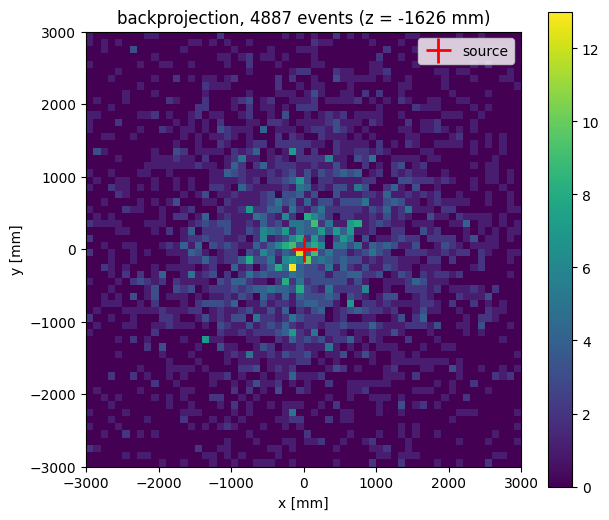

In [5]:
SRC = np.array([0.0, 0.0, -1626.0])   # mm

Kp = np.where(Ke > 0, Ke, np.nan)
rcs = Eg[:, None] * g_unit + (Kp * np.sqrt(1 + 2 * MC2 / Kp))[:, None] * e_unit
r_unit = rcs / np.linalg.norm(rcs, axis=1, keepdims=True)
d = -(Pe[:, 2] - SRC[2]) / r_unit[:, 2]
bp = Pe + d[:, None] * r_unit

R = 3000
fig, ax = plt.subplots(figsize=(6.5, 5.5))
h = ax.hist2d(bp[sel, 0], bp[sel, 1], bins=60, range=[[-R, R], [-R, R]], cmap="viridis")
ax.plot(SRC[0], SRC[1], "r+", ms=18, mew=2, label="source")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_aspect("equal")
ax.set_title(f"backprojection, {sel.sum()} events (z = {SRC[2]:.0f} mm)"); ax.legend()
fig.colorbar(h[3], ax=ax)
fig.tight_layout(); plt.show()

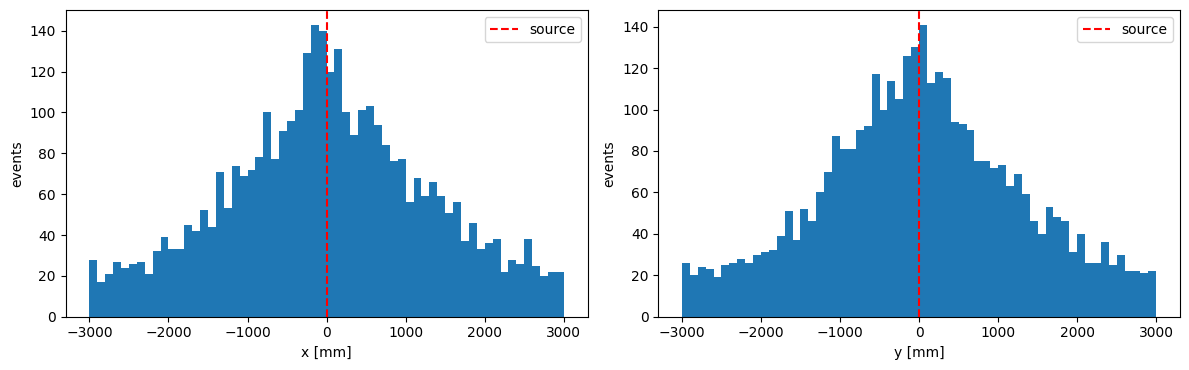

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, lab in enumerate("xy"):
    ax[k].hist(bp[sel, k], bins=60, range=(-R, R))
    ax[k].axvline(SRC[k], color="r", ls="--", label="source")
    ax[k].set_xlabel(f"{lab} [mm]"); ax[k].set_ylabel("events"); ax[k].legend()
fig.tight_layout(); plt.show()